In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 2.1

### a)

![task](tasks/1a.png)

![1a](drawings/1a.png)

### b)

![task](tasks/1b.png)

![1b](drawings/1b.png)

### c)

![task](tasks/1c.png)

In [35]:
f_real = lambda x: 1 / (1 + x) if (0 <= x <= 4) else None

n = 2
x = np.array([0, 1, 2]) # len = n + 1
f = np.array(list([f_real(i) for i in x]))

def f_dd(x, f):
    n = len(x)
    m = np.zeros((n, n))
    m[0] = f 
    for order in range(1, n):
        for j in range(n - order):
            m[order][j] = (m[order - 1][j + 1] - m[order - 1][j]) / (x[j+order] - x[j])
    return m

print(f_dd(x, f))


n = 3
x = np.array([0, 1, 2, 4]) # len = n + 1
f = np.array(list([f_real(i) for i in x]))

print(f_dd(x, f))

[[ 1.          0.5         0.33333333]
 [-0.5        -0.16666667  0.        ]
 [ 0.16666667  0.          0.        ]]
[[ 1.          0.5         0.33333333  0.2       ]
 [-0.5        -0.16666667 -0.06666667  0.        ]
 [ 0.16666667  0.03333333  0.          0.        ]
 [-0.03333333  0.          0.          0.        ]]


In [54]:
def Horner(x, x0, Newton_coefs):
    n = len(Newton_coefs)
    b = np.zeros(n)
    b[-1] = Newton_coefs[-1]
    for i in range(n-2, -1, -1):
        b[i] = Newton_coefs[i] + (x0 - x[i]) * b[i + 1]

    return b[0]

def Horners(x, Newton_coefs):
    return np.array(list([Horner(x, x_i, Newton_coefs) for x_i in x]))

Horners(x, f_dd(x, f)[:, 0])

array([1.        , 0.5       , 0.33333333, 0.2       ])

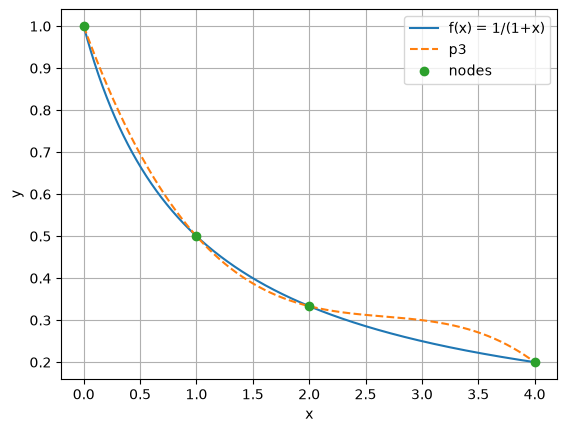

In [59]:
import matplotlib.pyplot as plt

x = np.array([0, 1, 2, 4])
f = 1 / (1 + x)
c = f_dd(x, f)[:, 0]

t = np.linspace(0, 4, 1001)
f_t = 1 / (1 + t)
p3_t = np.array([Horner(x, ti, c) for ti in t])

plt.plot(t, f_t, label="f(x) = 1/(1+x)")
plt.plot(t, p3_t, "--", label="p3")
plt.plot(x, f, "o", label="nodes")

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

In [61]:
err = np.max(np.abs(f_t - p3_t))
print(err)


0.053771139999245904


In [62]:
print(Horner(x, 3, c))

0.30000000000000004
